# Week 1: Retail Transaction EDA, Data Quality Audit & RFM Baseline

**Portable Stack:** `uv` (`pyproject.toml` + `uv.lock`) · VS Code · Local PostgreSQL (`.env`) · Power BI

Run each cell sequentially from `notebooks/week1_eda.ipynb` (or the project root).

## Block 1: Portable Setup, Data Ingestion & Anomaly Audit

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")

# Resolve project root whether running inside notebooks/ or root folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "online_retail_II_2009-10.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load environment variables from .env at project root
load_dotenv(ROOT / ".env")

# Load dataset with string IDs to preserve 'C'-prefixed cancellations and avoid float IDs
df = pd.read_csv(
    RAW_PATH,
    dtype={"Invoice": str, "StockCode": str, "Customer ID": str}
)

# Parse InvoiceDate (DD-MM-YY H:MM) and compute LineRevenue
df["InvoiceDate_dt"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")
df["LineRevenue"] = df["Quantity"] * df["Price"]

print("Project Root:", ROOT)
print("Raw Shape:", df.shape)
print("Date Range:", df["InvoiceDate_dt"].min(), "->", df["InvoiceDate_dt"].max())
print("\nMissing Values:\n", df.isna().sum())

C:\Users\acer\AppData\Local\Temp\ipykernel_12816\3448037359.py:28: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["InvoiceDate_dt"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")


Project Root: c:\Users\acer\Downloads\Consumer-360
Raw Shape: (525461, 10)
Date Range: 2009-12-01 07:45:00 -> 2010-12-09 20:01:00

Missing Values:
 Invoice                0
StockCode              0
Description         2928
Quantity               0
InvoiceDate            0
Price                  0
Customer ID       107927
Country                0
InvoiceDate_dt         0
LineRevenue            0
dtype: int64


In [2]:
# Inspect non-standard StockCodes (not starting with 5 digits)
weird_codes = df[~df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$", na=False)]
print("Unique non-standard StockCodes:", weird_codes["StockCode"].nunique())
weird_codes[["StockCode", "Description"]].drop_duplicates().head(30)

Unique non-standard StockCodes: 55


,StockCode,Description
89,POST,POSTAGE
735,D,Discount
2377,DCGS0058,MISO PRETTY GUM
2378,DCGS0068,DOGS NIGHT COLLAR
2379,DOT,DOTCOM POSTAGE
2697,M,Manual
8371,DCGS0004,HAYNES CAMPER SHOULDER BAG
8373,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
9292,C2,CARRIAGE
18410,BANK CHARGES,Bank Charges


In [3]:
# Quantify independent anomaly flags before cleaning
flags = {
    "Exact Duplicates": df.duplicated(),
    "Cancelled (C-prefix)": df["Invoice"].str.startswith("C", na=False),
    "Quantity <= 0": df["Quantity"] <= 0,
    "Price <= 0": df["Price"] <= 0,
    "Missing Customer ID": df["Customer ID"].isna(),
}

audit_rows = []
for name, mask in flags.items():
    audit_rows.append({
        "Anomaly": name,
        "Rows": int(mask.sum()),
        "Pct_of_Raw": round(mask.mean() * 100, 2),
        "Revenue_Impact": round(df.loc[mask, "LineRevenue"].sum(), 2)
    })

pd.DataFrame(audit_rows)

,Anomaly,Rows,Pct_of_Raw,Revenue_Impact
0,Exact Duplicates,6865,1.31,33709.07
1,Cancelled (C-prefix),10206,1.94,-629855.37
2,Quantity <= 0,12326,2.35,-630228.94
3,Price <= 0,3690,0.70,-136552.02
4,Missing Customer ID,107927,20.54,1191276.06


## Block 2: Sequential Cleaning Waterfall & Core Commercial KPIs

In [4]:
# Non-product operational, fee, adjustment, and test StockCodes
non_prod_codes = {
    "POST", "DOT", "M", "m", "D", "C2", "BANK CHARGES",
    "ADJUST", "ADJUST2", "TEST001", "TEST002", "S", "B", "AMAZONFEE"
}

waterfall = []
def log_step(label, frame):
    waterfall.append({
        "Stage": label,
        "Rows": len(frame),
        "Pct_of_Raw": round(len(frame) / len(df) * 100, 2),
        "Net_Revenue": round(frame["LineRevenue"].sum(), 2)
    })

log_step("0. Raw Dataset", df)

clean = df.drop_duplicates().copy()
log_step("1. Drop Exact Duplicates", clean)

clean = clean[~clean["Invoice"].str.startswith("C", na=False)]
log_step("2. Remove C-Prefix Cancellations", clean)

clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
log_step("3. Remove Qty <= 0 or Price <= 0", clean)

clean = clean[~clean["StockCode"].isin(non_prod_codes)]
log_step("4. Remove Non-Product StockCodes", clean)

guest_rev = clean.loc[clean["Customer ID"].isna(), "LineRevenue"].sum()
print(f"Unidentified Guest Revenue (valid product rows without Customer ID): {guest_rev:,.2f}")

clean = clean.dropna(subset=["Customer ID"]).copy()
clean["Customer ID"] = clean["Customer ID"].str.replace(r"\.0$", "", regex=True)
log_step("5. Drop Missing Customer ID (Identified Base)", clean)

pd.DataFrame(waterfall)

Unidentified Guest Revenue (valid product rows without Customer ID): 1,166,060.39


,Stage,Rows,Pct_of_Raw,Net_Revenue
0,0. Raw Dataset,525461,100.00,9539484.63
1,1. Drop Exact Duplicates,518596,98.69,9505775.56
2,2. Remove C-Prefix Cancellations,508414,96.76,10135210.64
3,3. Remove Qty <= 0 or Price <= 0,504730,96.05,10271762.66
4,4. Remove Non-Product StockCodes,502476,95.63,9805717.60
5,5. Drop Missing Customer ID (Identified Base),399568,76.04,8639657.21


In [5]:
# Core Commercial KPIs (Cleaned Identified Dataset)
total_rev = clean["LineRevenue"].sum()
total_orders = clean["Invoice"].nunique()
unique_customers = clean["Customer ID"].nunique()
unique_skus = clean["StockCode"].nunique()
total_units = clean["Quantity"].sum()

aov = total_rev / total_orders
basket_size = total_units / total_orders

print(f"Total Net Revenue : {total_rev:,.2f}")
print(f"Total Orders      : {total_orders:,}")
print(f"Unique Customers  : {unique_customers:,}")
print(f"Unique SKUs       : {unique_skus:,}")
print(f"Average Order Val : {aov:,.2f}")
print(f"Basket Size       : {basket_size:,.2f} units/order")

Total Net Revenue : 8,639,657.21
Total Orders      : 18,966
Unique Customers  : 4,285
Unique SKUs       : 4,008
Average Order Val : 455.53
Basket Size       : 290.75 units/order


## Exploratory Breakdowns & Visuals

In [6]:
# Top 10 Products by Revenue and Country Revenue Breakdown
top_rev = clean.groupby(["StockCode", "Description"]).agg(
    Revenue=("LineRevenue", "sum"),
    Quantity=("Quantity", "sum"),
    Orders=("Invoice", "nunique")
).sort_values("Revenue", ascending=False).head(10)

display(top_rev)

by_country = clean.groupby("Country").agg(
    Revenue=("LineRevenue", "sum"),
    Orders=("Invoice", "nunique"),
    Customers=("Customer ID", "nunique")
).sort_values("Revenue", ascending=False)
by_country["Rev_Share_Pct"] = (by_country["Revenue"] / total_rev * 100).round(2)
display(by_country.head(10))

,,Revenue,Quantity,Orders
StockCode,Description,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,151339.16,56814,3021
22423,REGENCY CAKESTAND 3 TIER,143727.60,12484,1687
84879,ASSORTED COLOUR BIRD ORNAMENT,70291.03,44431,1333
85099B,JUMBO BAG RED RETROSPOT,51644.25,29519,1060
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,40156.05,21579,244
22086,PAPER CHAIN KIT 50'S CHRISTMAS,36871.55,13839,796
47566,PARTY BUNTING,35017.30,8312,710
15056N,EDWARDIAN PARASOL NATURAL,34044.75,7201,496
85099F,JUMBO BAG STRAWBERRY,33926.25,19275,876


,Revenue,Orders,Customers,Rev_Share_Pct
Country,,,,
United Kingdom,7323113.103,17497,3953,84.76
EIRE,334196.740,281,3,3.87
Netherlands,266061.670,124,22,3.08
Germany,182889.931,325,67,2.12
France,131261.640,222,45,1.52
Denmark,50348.850,25,9,0.58
Sweden,49216.310,64,16,0.57
Spain,42854.910,58,22,0.50
Switzerland,41182.390,36,14,0.48


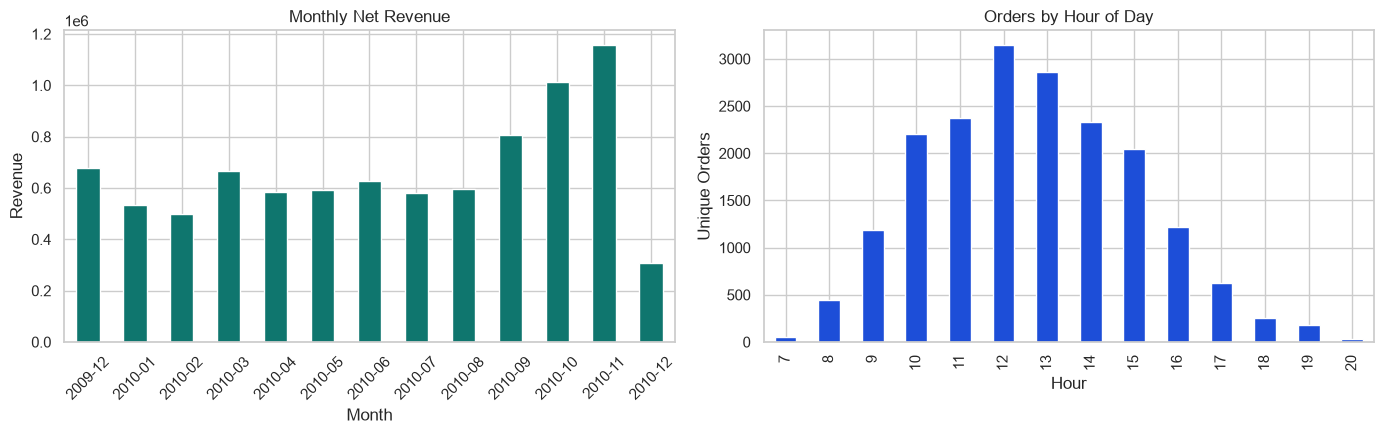

In [7]:
# Temporal & Intraday Charts
clean["YearMonth"] = clean["InvoiceDate_dt"].dt.to_period("M").astype(str)
clean["Hour"] = clean["InvoiceDate_dt"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

monthly = clean.groupby("YearMonth")["LineRevenue"].sum()
monthly.plot(kind="bar", ax=axes[0], color="#0F766E")
axes[0].set_title("Monthly Net Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)

hourly = clean.groupby("Hour")["Invoice"].nunique()
hourly.plot(kind="bar", ax=axes[1], color="#1D4ED8")
axes[1].set_title("Orders by Hour of Day")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Unique Orders")

plt.tight_layout()
plt.show()

## Customer-Level RFM Baseline & Pareto Check

In [8]:
ref_date = clean["InvoiceDate_dt"].max() + pd.Timedelta(days=1)

rfm = clean.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate_dt", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("LineRevenue", "sum"),
    TotalUnits=("Quantity", "sum"),
    Country=("Country", "first")
).reset_index()

rfm["Recency"] = (ref_date - rfm["LastPurchase"]).dt.days
rfm["AvgOrderValue"] = rfm["Monetary"] / rfm["Frequency"]

# Quartile scores (4 = best)
rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

rfm = rfm.sort_values("Monetary", ascending=False)
display(rfm.head(10))

# Pareto 80/20 check
top_10_n = int(np.ceil(len(rfm) * 0.10))
top_20_n = int(np.ceil(len(rfm) * 0.20))
print(f"Top 10% ({top_10_n} customers) Revenue Share: {rfm.head(top_10_n)['Monetary'].sum() / rfm['Monetary'].sum() * 100:.2f}%")
print(f"Top 20% ({top_20_n} customers) Revenue Share: {rfm.head(top_20_n)['Monetary'].sum() / rfm['Monetary'].sum() * 100:.2f}%")

,Customer ID,LastPurchase,Frequency,Monetary,TotalUnits,Country,Recency,AvgOrderValue,R_Score,F_Score,M_Score,RFM_Score
4156,18102,2010-12-09 13:44:00,89,349164.35,124216,United Kingdom,1,3923.194944,4,4,4,12
1620,14646,2010-11-30 16:28:00,73,247613.50,170228,Netherlands,10,3391.965753,4,4,4,12
1256,14156,2010-12-03 11:48:00,91,186832.00,108074,EIRE,7,2053.098901,4,4,4,12
1820,14911,2010-12-09 12:17:00,183,140352.54,69624,EIRE,1,766.953770,4,4,4,12
928,13694,2010-12-01 12:12:00,94,131443.19,125893,United Kingdom,9,1398.331809,4,4,4,12
3718,17511,2010-12-07 09:51:00,31,84541.17,55107,United Kingdom,3,2727.134516,4,4,4,12
1931,15061,2010-12-07 13:50:00,86,83282.93,51790,United Kingdom,3,968.406163,4,4,4,12
3103,16684,2010-11-25 11:04:00,27,80489.21,54555,United Kingdom,15,2981.081852,4,4,4,12
3152,16754,2010-12-02 17:38:00,29,65500.07,63551,United Kingdom,8,2258.623103,4,4,4,12
496,13089,2010-12-06 14:00:00,109,57885.45,29125,United Kingdom,4,531.059174,4,4,4,12


Top 10% (429 customers) Revenue Share: 59.79%
Top 20% (857 customers) Revenue Share: 73.38%


## Block 3: Save Processed CSVs & Load into Local PostgreSQL

Make sure your `.env` file in the project root defines `PG_USER`, `PG_PASSWORD`, `PG_HOST`, `PG_PORT`, and `PG_DB` (e.g., `retail_analytics`).

In [9]:
# Rename columns to snake_case for PostgreSQL & Power BI
clean_pg = clean.rename(columns={
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate_dt": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country",
    "LineRevenue": "line_revenue",
    "YearMonth": "year_month",
    "Hour": "hour"
}).drop(columns=["InvoiceDate"])

rfm_pg = rfm.rename(columns={
    "Customer ID": "customer_id",
    "LastPurchase": "last_purchase",
    "Frequency": "frequency",
    "Monetary": "monetary",
    "TotalUnits": "total_units",
    "Country": "country",
    "Recency": "recency",
    "AvgOrderValue": "avg_order_value",
    "R_Score": "r_score",
    "F_Score": "f_score",
    "M_Score": "m_score",
    "RFM_Score": "rfm_score"
})

# Save portable processed CSVs
clean_pg.to_csv(PROCESSED_DIR / "cleaned_retail_week1.csv", index=False)
rfm_pg.to_csv(PROCESSED_DIR / "customer_rfm_week1.csv", index=False)
print("Saved processed CSVs to:", PROCESSED_DIR)

Saved processed CSVs to: c:\Users\acer\Downloads\Consumer-360\data\processed


In [10]:
from sqlalchemy import create_engine, text

pg_user = os.getenv("PG_USER", "postgres")
pg_password = os.getenv("PG_PASSWORD")
pg_host = os.getenv("PG_HOST", "localhost")
pg_port = os.getenv("PG_PORT", "5432")
pg_db = os.getenv("PG_DB", "retail_analytics")

if not pg_password:
    raise ValueError("PG_PASSWORD not found. Check your .env file in the project root.")

# 1. Connect to default 'postgres' DB to create 'retail_analytics' if missing
admin_engine = create_engine(
    f"postgresql+psycopg2://{pg_user}:{pg_password}@{pg_host}:{pg_port}/postgres",
    isolation_level="AUTOCOMMIT",
)
with admin_engine.connect() as conn:
    exists = conn.execute(text("SELECT 1 FROM pg_database WHERE datname = :db"), {"db": pg_db}).scalar()
    if not exists:
        conn.execute(text(f'CREATE DATABASE "{pg_db}"'))
        print(f"Created database {pg_db}!")

# 2. Load both tables into retail_analytics
engine = create_engine(f"postgresql+psycopg2://{pg_user}:{pg_password}@{pg_host}:{pg_port}/{pg_db}")
clean_pg.to_sql("cleaned_transactions", engine, if_exists="replace", index=False, chunksize=10000)
rfm_pg.to_sql("customer_rfm", engine, if_exists="replace", index=False)
print(f"Successfully loaded cleaned_transactions and customer_rfm into {pg_db}!")

Created database retail_analytics!
Successfully loaded cleaned_transactions and customer_rfm into retail_analytics!
